In [74]:
# pip install seaborn
# pip install openpyxl

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl
import datetime

In [44]:
df = pd.read_csv("Superstore_Sales.csv")

In [45]:
display(df.head())


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [46]:
df.shape

(9800, 18)

In [47]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

Analysis

In [63]:
print("Total Sales:",df['Sales'].sum())
print('Average Sales:', df['Sales'].mean())
print('Top category:', df.groupby("Category")['Sales'].sum().idxmax())
print('Top Region:', df.groupby('Region')['Sales'].sum().idxmax())

top_customers = df.groupby("Customer Name")["Sales"].sum().nlargest(5)
print("\nTop 5 Customers:\n", top_customers)

Total Sales: 2261536.7827000003
Average Sales: 230.7690594591837
Top category: Technology
Top Region: West

Top 5 Customers:
 Customer Name
Sean Miller      25043.050
Tamara Chand     19052.218
Raymond Buch     15117.339
Tom Ashbrook     14595.620
Adrian Barton    14473.571
Name: Sales, dtype: float64


Monthly Sales

In [49]:
df['Order Date'] = pd.to_datetime(df['Order Date'], format="%d/%m/%Y")
df['Month'] = df['Order Date'].dt.month
print(df.groupby('Month')['Sales'].sum())

Month
1      94291.6296
2      59371.1154
3     197573.5872
4     136283.0006
5     154086.7237
6     145837.5233
7     145535.6890
8     157315.9270
9     300103.4117
10    199496.2947
11    350161.7110
12    321480.1695
Name: Sales, dtype: float64


Visualization

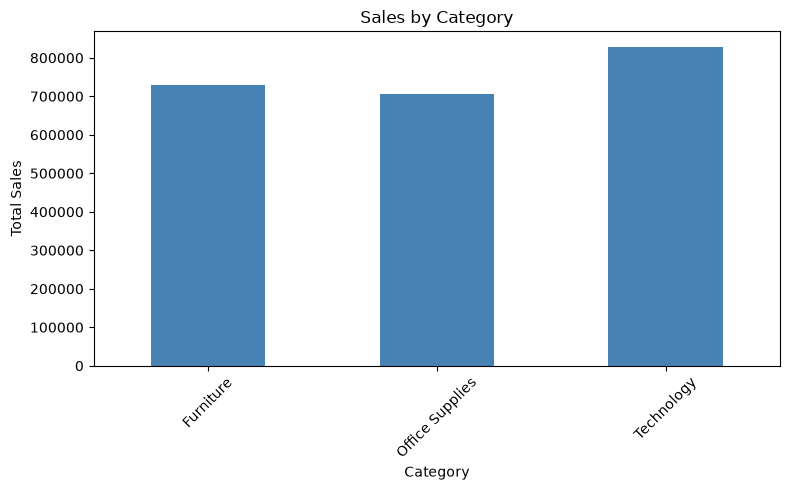

In [55]:
# Chart 1 — Sales by Category

category_sales = df.groupby("Category")["Sales"].sum()

plt.figure(figsize=(8, 5))
category_sales.plot(kind="bar", color="steelblue")
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("sales_by_category.png")
plt.show()

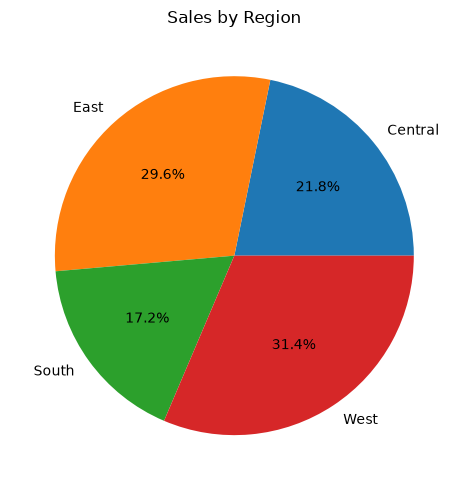

In [59]:
# Chart 2 — Sales by Region

region_sales = df.groupby("Region")["Sales"].sum()

plt.figure(figsize=(8, 5))
region_sales.plot(kind="pie", autopct="%1.1f%%")
plt.title("Sales by Region")
plt.tight_layout()
plt.savefig("sales_by_region.png")
plt.show()

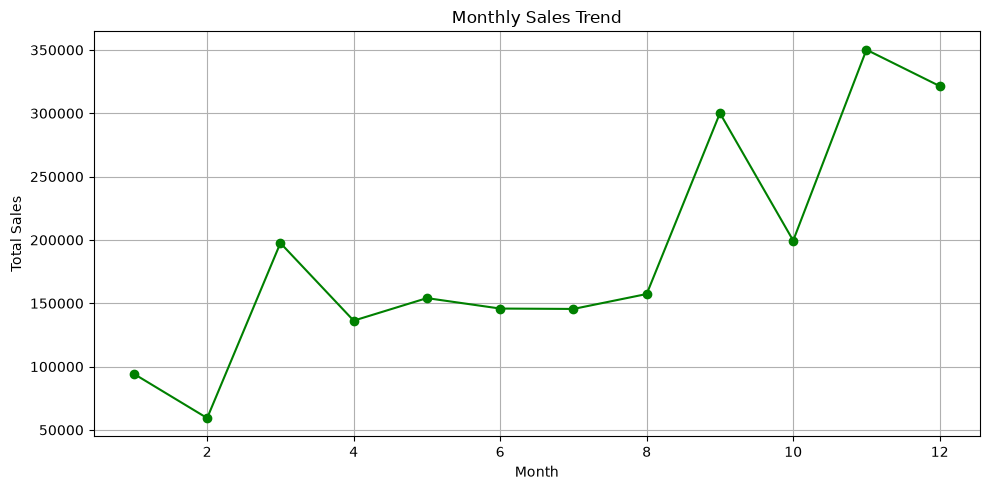

In [57]:
# Chart 3 — Monthly Sales Trend

monthly_sales = df.groupby("Month")["Sales"].sum()

plt.figure(figsize=(10, 5))
monthly_sales.plot(kind="line", marker="o", color="green")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True)
plt.tight_layout()
plt.savefig("monthly_sales_trend.png")
plt.show()

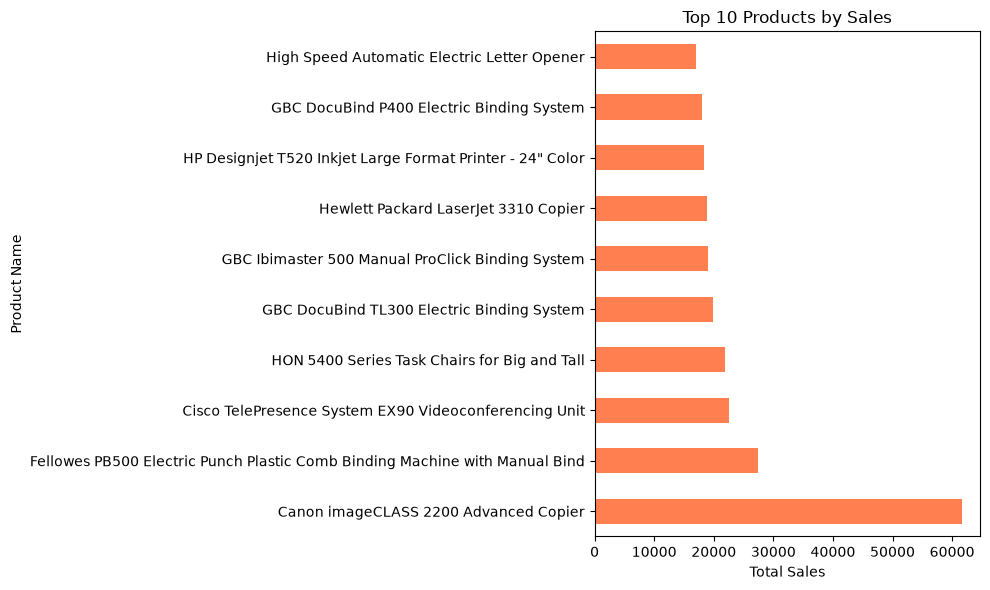

In [53]:
# Chart 4 — Top 10 Products by Sales

top_products = df.groupby("Product Name")["Sales"].sum().nlargest(10)

plt.figure(figsize=(10, 6))
top_products.plot(kind="barh", color="coral")
plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.tight_layout()
plt.savefig("top_products.png")
plt.show()

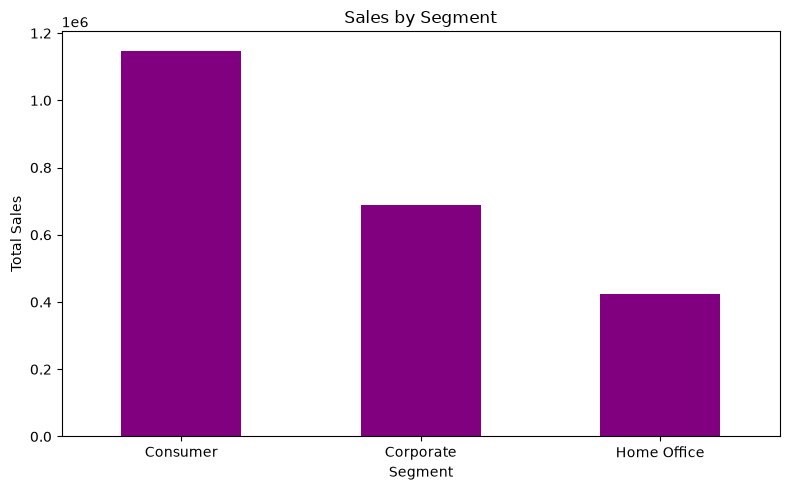

In [65]:
# Chart 5 — Sales by Segment

segment_sales = df.groupby("Segment")["Sales"].sum()

plt.figure(figsize=(8, 5))
segment_sales.plot(kind="bar", color="purple")
plt.title("Sales by Segment")
plt.xlabel("Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("sales_by_segment.png")
plt.show()

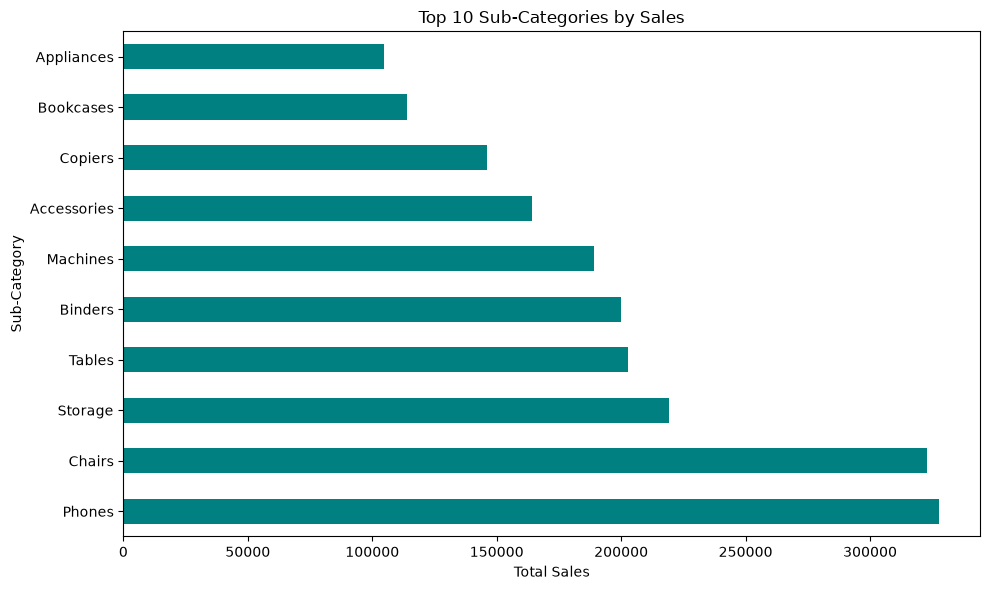

In [66]:
# Chart 6 — Top 10 Sub-Categories by Sales

subcategory_sales = df.groupby("Sub-Category")["Sales"].sum().nlargest(10)

plt.figure(figsize=(10, 6))
subcategory_sales.plot(kind="barh", color="teal")
plt.title("Top 10 Sub-Categories by Sales")
plt.xlabel("Total Sales")
plt.tight_layout()
plt.savefig("subcategory_sales.png")
plt.show()

In [75]:
df.to_excel("superstore_cleaned.xlsx", index=False)
print("Exported successfully!")

Exported successfully!
